# 03 · Delta-hedging : simulation Monte Carlo

> 📘 Notebook compagnon du cours [Les grecques en finance](https://pgu.github.io/pi-gamma-upsilon/). Le code Python reproduit ce que font les playgrounds du site, avec les **mêmes conventions de desk** : vega par point de vol, theta par jour, rho par point de taux.
>
> **Installation** (une fois) : `pip install -r requirements.txt`, puis `jupyter lab`. Lance ce notebook depuis le dossier `notebooks/`.

**Leçon liée :** « Pro : delta-hedging en action ».

**Idée :** on vend un call ATM à 60 jours à une volatilité *implicite* σᵢ, on se couvre en delta, et le spot évolue avec une volatilité *réalisée* σᵣ. Le P&L final dépend de **σᵣ − σᵢ** (et non du sens du marché).

**Objectifs :** coder la simulation (vectorisée), mesurer l'effet de la fréquence de rééquilibrage, vérifier la relation P&L ≈ vega × (σᵢ − σᵣ), puis ajouter des coûts de transaction.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import greeks as g          # notre petite bibliothèque (voir greeks.py)

plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format

## 1. La simulation

Taux nul pour simplifier la comptabilité. À chaque date de rééquilibrage on ajuste le nombre d'actions détenues au nouveau delta ; la trésorerie absorbe les achats/ventes (et les coûts).

P&L final = trésorerie + actions détenues × spot final − payoff du call vendu.

In [2]:
def hedge_pnl(sig_i, sig_r, every=1, n=60, K=100, S0=100, paths=4000, tc=0.0, seed=0):
    """Vend 1 call ATM à sig_i, le couvre en delta tous les `every` jours (0 = jamais, après la mise en place).
    tc = coût proportionnel au montant échangé (ex. 0.0005 = 5 bp)."""
    rng = np.random.default_rng(seed)
    dt = 1 / 365
    z = rng.standard_normal((paths, n))
    S = S0 * np.exp(np.cumsum(-0.5 * sig_r**2 * dt + sig_r * np.sqrt(dt) * z, axis=1))
    S = np.concatenate([np.full((paths, 1), S0), S], axis=1)           # (paths, n+1)

    g0 = g.greeks(S0, K, n / 365, 0.0, sig_i, "call")
    premium, d = float(g0["price"]), np.full(paths, float(g0["delta"]))
    cash = premium - d * S0 - tc * np.abs(d) * S0
    deltas = [d.copy()]
    for i in range(1, n + 1):
        if i < n and every and i % every == 0:
            nd = g.greeks(S[:, i], K, (n - i) / 365, 0.0, sig_i, "call")["delta"]
            trade = nd - d
            cash = cash - trade * S[:, i] - tc * np.abs(trade) * S[:, i]
            d = nd
        deltas.append(d.copy())
    pnl = cash + d * S[:, n] - np.maximum(S[:, n] - K, 0)
    return dict(S=S, delta=np.array(deltas).T, pnl=pnl, premium=premium)

## 2. Un chemin

Le spot (en haut) et le delta de la couverture (en bas) pour un chemin tiré au hasard.

Premium encaissée : 3.23   P&L final du trade couvert : +0.13


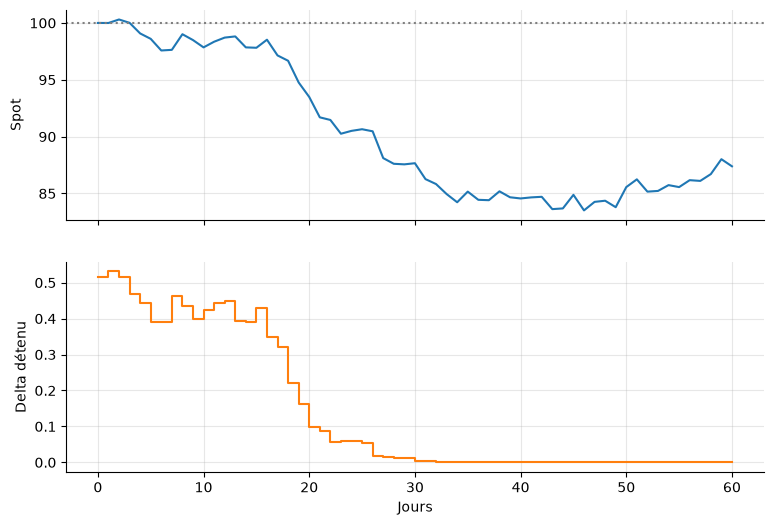

In [3]:
sim = hedge_pnl(0.20, 0.20, every=1, paths=1, seed=7)
fig, (a, b) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
a.plot(sim["S"][0]); a.axhline(100, color="gray", ls=":"); a.set_ylabel("Spot")
b.step(range(len(sim["delta"][0])), sim["delta"][0], color="C1"); b.set_ylabel("Delta détenu"); b.set_xlabel("Jours")
print(f"Premium encaissée : {sim['premium']:.2f}   P&L final du trade couvert : {sim['pnl'][0]:+.2f}")

## 3. Quand σᵣ = σᵢ : l'espérance est nulle

On lance 4 000 chemins avec des fréquences de rééquilibrage différentes. Le P&L **moyen** est ≈ 0 (à l'erreur Monte Carlo près), mais la **dispersion** dépend fortement de la fréquence.

In [4]:
rows = {}
for label, every in [("quotidien", 1), ("hebdo", 5), ("aucun", 0)]:
    pnl = hedge_pnl(0.20, 0.20, every=every)["pnl"]
    rows[label] = {"P&L moyen": pnl.mean(), "écart-type": pnl.std(), "erreur std de la moyenne": pnl.std() / np.sqrt(len(pnl))}
summary = pd.DataFrame(rows).T
summary

,P&L moyen,écart-type,erreur std de la moyenne
quotidien,-0.0074,0.3631,0.0057
hebdo,0.0041,0.7919,0.0125
aucun,-0.0384,2.4915,0.0394


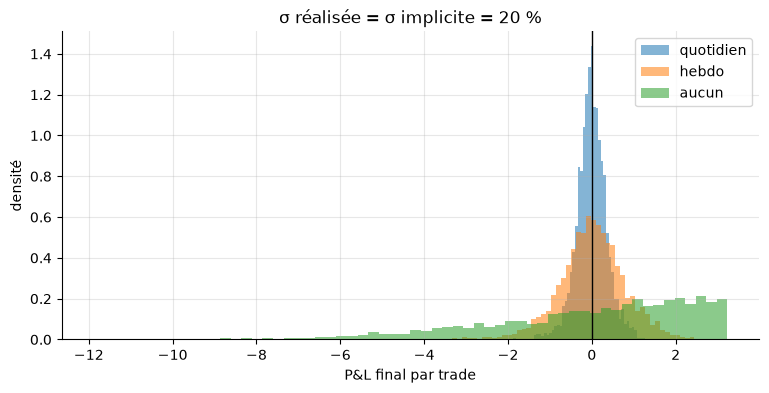

In [5]:
fig, ax = plt.subplots()
for label, every in [("quotidien", 1), ("hebdo", 5), ("aucun", 0)]:
    ax.hist(hedge_pnl(0.20, 0.20, every=every)["pnl"], bins=60, alpha=.55, label=label, density=True)
ax.axvline(0, color="k", lw=1)
ax.set(xlabel="P&L final par trade", ylabel="densité", title="σ réalisée = σ implicite = 20 %")
ax.legend();

## 4. Le P&L vient de σᵣ − σᵢ

On fait varier la vol réalisée. Pour une option ATM, le P&L moyen d'un trade couvert quotidiennement est proche de **vega × (σᵢ − σᵣ)** (en points de vol) : c'est la lecture « vol trader » du delta-hedging.

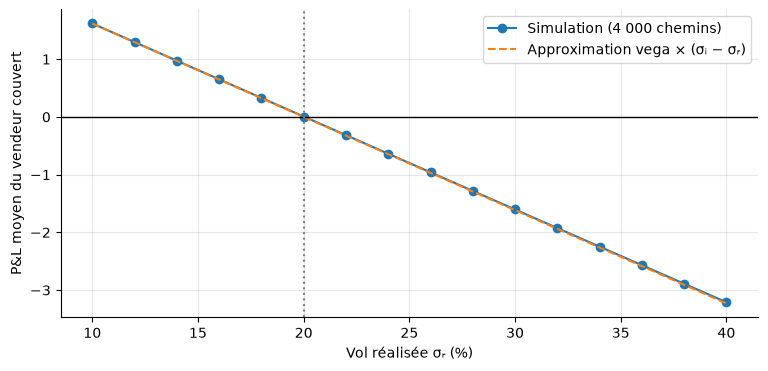

In [6]:
sig_i = 0.20
vega0 = float(g.greeks(100, 100, 60 / 365, 0.0, sig_i, "call")["vega"])      # par point de vol
sig_rs = np.arange(0.10, 0.401, 0.02)
mean_pnl = [hedge_pnl(sig_i, s, every=1, seed=1).get("pnl").mean() for s in sig_rs]
approx = [vega0 * (sig_i - s) * 100 for s in sig_rs]

fig, ax = plt.subplots()
ax.plot(sig_rs * 100, mean_pnl, "o-", label="Simulation (4 000 chemins)")
ax.plot(sig_rs * 100, approx, "--", label="Approximation vega × (σᵢ − σᵣ)")
ax.axhline(0, color="k", lw=1); ax.axvline(sig_i * 100, color="gray", ls=":")
ax.set(xlabel="Vol réalisée σᵣ (%)", ylabel="P&L moyen du vendeur couvert")
ax.legend();

Vendeur couvert : **gagne** si σᵣ < σᵢ (il a vendu la vol trop chère), **perd** si σᵣ > σᵢ. Pour une option ATM de maturité courte, la droite « vega × écart de vol » colle presque parfaitement à la simulation, même pour de gros écarts : le P&L moyen du trade couvert est quasi linéaire en σᵣ.

## 5. Les coûts de transaction

Rééquilibrer plus souvent réduit la dispersion mais coûte plus cher. Avec un coût de **5 points de base** sur chaque montant échangé :

In [7]:
rows = {}
for label, every in [("quotidien", 1), ("hebdo", 5), ("aucun", 0)]:
    base = hedge_pnl(0.20, 0.20, every=every, seed=3)["pnl"]
    costly = hedge_pnl(0.20, 0.20, every=every, tc=0.0005, seed=3)["pnl"]
    rows[label] = {"écart-type": costly.std(), "P&L moyen sans coût": base.mean(), "P&L moyen avec coût": costly.mean(), "coût moyen": base.mean() - costly.mean()}
pd.DataFrame(rows).T

,écart-type,P&L moyen sans coût,P&L moyen avec coût,coût moyen
quotidien,0.3738,0.0044,-0.1445,0.1488
hebdo,0.7897,0.0132,-0.0648,0.0780
aucun,2.3807,0.0869,0.0611,0.0258


### À toi de jouer

1. Dessine l'histogramme pour `sig_r = 0.30` et `sig_i = 0.20` : le P&L moyen est-il négatif ? Quelle est la probabilité de perte ?
2. Cherche la fréquence de rééquilibrage (1, 2, 5, 10 jours) qui minimise `coût moyen + k × écart-type` pour un `k` de ton choix. C'est exactement l'arbitrage précision / coûts d'un desk.
3. Remplace le call ATM par un call OTM (`K=110`) : la dispersion augmente-t-elle ? Pourquoi (pense au gamma) ?